# 02 — Time-based split

Train on the first four months, tune on the fifth, evaluate once on the sixth. Random splitting is not used:
it leaks future information into training and overstates the quality of fraud models.

In [23]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from fraud.data import load_train
from fraud.split import time_split

sns.set_theme(style="whitegrid")

In [24]:
df = load_train()
train, valid, test = time_split(df)
for name, part in [('train', train), ('valid', valid), ('test', test)]:
    print(f"{name}: {len(part)} rows ({len(part) / len(df):.1%}), fraud rate {part['isFraud'].mean():.2%}")

assert len(train) + len(valid) + len(test) == len(df)

train: 414542 rows (70.2%), fraud rate 3.52%
valid: 83571 rows (14.2%), fraud rate 3.41%
test: 92427 rows (15.7%), fraud rate 3.48%


## 1. Timeline

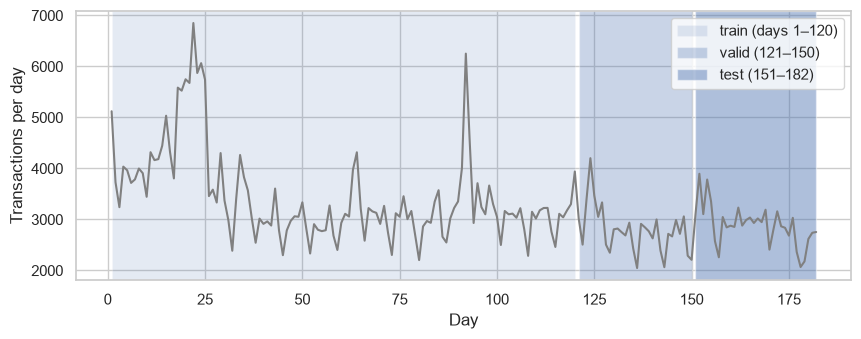

In [25]:
SECONDS_PER_DAY = 24 * 60 * 60
daily = df.groupby(df["TransactionDT"] // SECONDS_PER_DAY).size()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily.index, daily.values, color="gray")
ax.axvspan(1, 120, alpha=0.15, label="train (days 1–120)")
ax.axvspan(121, 150, alpha=0.3, label="valid (121–150)")
ax.axvspan(151, 182, alpha=0.45, label="test (151–182)")
ax.set_xlabel("Day")
ax.set_ylabel("Transactions per day")
ax.legend(loc="upper right")
plt.show()

## 2. Experiment: random split vs time split

Same model, same amount of training data, two ways of choosing it. The holdout is the remaining 30% in both cases.

In [26]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score

y = df['isFraud']
X = df.drop(columns = ['isFraud', 'TransactionDT','TransactionID'])
day = df["TransactionDT"] // SECONDS_PER_DAY

MODEL_PARAMS = dict(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=63,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.5,
    n_jobs=2,
    verbose=-1,
)

In [29]:
def evaluate(train_mask, name):
    """Fit on rows where train_mask is True, score the rest."""
    model = lgb.LGBMClassifier(**MODEL_PARAMS).fit(X[train_mask], y[train_mask])
    scores = model.predict_proba(X[~train_mask])[:, 1]
    y_holdout = y[~train_mask]
    print(f"{name:<12} ROC-AUC {roc_auc_score(y_holdout, scores):.4f}   PR-AUC {average_precision_score(y_holdout, scores):.4f}")


rng = np.random.default_rng(42)
random_mask = rng.random(len(df)) < 0.70
time_mask = day <= 120

evaluate(random_mask, "random")
evaluate(time_mask, "time")

random       ROC-AUC 0.9490   PR-AUC 0.7606
time         ROC-AUC 0.9138   PR-AUC 0.5584


The same LightGBM model scores PR-AUC 0.76 on a random holdout but only 0.56 on the following two months.
Random splitting lets the model see transactions from the same cards and fraud series as the holdout, so it
overstates real-world quality by a wide margin. Note how ROC-AUC hides most of the gap (0.95 vs 0.91) while
PR-AUC exposes it. All further evaluation in this project is time-based; the test month is used once, at the end.